### 1. Set up ###

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, roc_curve, balanced_accuracy_score, recall_score,
                             accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import calibration_curve
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Find the project folder whether the notebook runs from notebooks/ or from the top folder
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
sys.path.insert(0, str(ROOT / "notebooks"))
os.chdir(ROOT)                       # train_baseline uses paths like data/manifest_split.csv
import train_baseline as tb

SPLIT = "val"                        # change to "test" ONCE, when the model is final
N_BOOT = 2000                        # bootstrap resamples for confidence intervals
RNG = np.random.default_rng(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if SPLIT == "test":
    print("⚠️  Evaluating on the TEST set. Don't change the model after looking at these numbers.")
print("device:", device, "| evaluating on:", SPLIT)

device: cpu | evaluating on: val


### CNN predictions, one row per subject ###

In [3]:
import re

manifest = pd.read_csv(tb.MANIFEST_SPLIT)

# The manifest stores Windows paths (F:\...). Rebuild them for this computer from the file name.
PT_DIR = ROOT / "data" / "MRI" / "Axial" / "pt_files"
manifest["pt_path"] = [str(PT_DIR / re.split(r"[\\/]", p)[-1]) for p in manifest["pt_path"]]
missing = [p for p in manifest["pt_path"] if not Path(p).exists()]
print(f"{len(manifest) - len(missing)} of {len(manifest)} scan files found")
assert not missing, f"missing scan files, e.g. {missing[:3]}"

subject_info = manifest.drop_duplicates("sub_id")[["sub_id", "age", "sex"]]

model = tb.Baseline3DCNN().to(device)
model.load_state_dict(torch.load(tb.CHECKPOINT, map_location=device))

def subject_predictions(split):
    """CNN probability of autism for each subject in a split (scans averaged per subject)."""
    scans = manifest[manifest["split"] == split]
    subj = tb.per_subject(tb.predict(model, scans, batch_size=4, device=device))
    return subj.merge(subject_info, on="sub_id")

val = subject_predictions("val")
ev = val.copy() if SPLIT == "val" else subject_predictions(SPLIT)
print(f"{len(ev)} subjects, {int(ev['label'].sum())} autism, {int((ev['label'] == 0).sum())} control")
ev.head()

129 of 129 scan files found
20 subjects, 10 autism, 10 control


,sub_id,label,site,prob,age,sex
0,50272,1,UM_1,0.527630,14.2,1
1,50282,1,UM_1,0.519397,15.2,1
2,50283,1,UM_1,0.535483,11.2,1
3,50286,1,UM_1,0.537613,11.2,1
4,50288,1,UM_1,0.527759,11.1,1


### Choose the decision threshold on the validation set ###

In [4]:
def youden_threshold(y, p):
    """Threshold that maximizes sensitivity + specificity - 1."""
    fpr, tpr, thr = roc_curve(y, p)
    thr = np.minimum(thr, 1.0)               # roc_curve's first threshold is inf
    return float(thr[np.argmax(tpr - fpr)])

THRESHOLD = youden_threshold(val["label"], val["prob"])
print(f"CNN decision threshold (chosen on validation): {THRESHOLD:.3f}")

CNN decision threshold (chosen on validation): 0.519


### Metrics with 95% confidence intervals ###

In [5]:
def metrics(y, p, threshold):
    y, p = np.asarray(y), np.asarray(p)
    yhat = (p >= threshold).astype(int)
    two_classes = len(np.unique(y)) == 2
    return {
        "AUC": roc_auc_score(y, p) if two_classes else np.nan,
        "Balanced acc": balanced_accuracy_score(y, yhat) if two_classes else np.nan,
        "Sensitivity": recall_score(y, yhat, pos_label=1, zero_division=np.nan),
        "Specificity": recall_score(y, yhat, pos_label=0, zero_division=np.nan),
        "Accuracy": accuracy_score(y, yhat),
    }

def bootstrap(y, p, threshold, n_boot=N_BOOT):
    """Resample subjects (within each class) to show how much each metric could move."""
    y, p = np.asarray(y), np.asarray(p)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    draws = []
    for _ in range(n_boot):
        idx = np.concatenate([RNG.choice(pos, len(pos)), RNG.choice(neg, len(neg))])
        draws.append(metrics(y[idx], p[idx], threshold))
    draws = pd.DataFrame(draws)
    return pd.DataFrame({
        "estimate": pd.Series(metrics(y, p, threshold)),
        "ci_low": draws.quantile(0.025),
        "ci_high": draws.quantile(0.975),
    }).round(3)

cnn_results = bootstrap(ev["label"], ev["prob"], THRESHOLD)
cnn_results

,estimate,ci_low,ci_high
AUC,0.90,0.73,1.0
Balanced acc,0.85,0.70,1.0
Sensitivity,1.00,1.00,1.0
Specificity,0.70,0.40,1.0
Accuracy,0.85,0.70,1.0


### Baselines and a permutation test ###

In [6]:
# (a) Confounder-only model: can age + sex + site alone predict the diagnosis?
features = ["age", "sex", "site"]
train_subj = manifest[manifest["split"] == "train"].drop_duplicates("sub_id")
confounder_model = make_pipeline(
    make_column_transformer(
        (StandardScaler(), ["age"]),
        (OneHotEncoder(handle_unknown="ignore"), ["sex", "site"]),
    ),
    LogisticRegression(max_iter=1000),
)
confounder_model.fit(train_subj[features], train_subj["label"])
val["prob_conf"] = confounder_model.predict_proba(val[features])[:, 1]
ev["prob_conf"] = confounder_model.predict_proba(ev[features])[:, 1]
conf_threshold = youden_threshold(val["label"], val["prob_conf"])

# (b) Majority-class guess: same probability for everyone
ev["prob_majority"] = train_subj["label"].mean()

def summary_row(name, prob_col, threshold):
    r = bootstrap(ev["label"], ev[prob_col], threshold)
    return {"model": name,
            **{m: f"{r.loc[m, 'estimate']:.2f} [{r.loc[m, 'ci_low']:.2f}, {r.loc[m, 'ci_high']:.2f}]"
               for m in ["AUC", "Balanced acc", "Sensitivity", "Specificity"]}}

comparison = pd.DataFrame([
    summary_row("Majority class", "prob_majority", 0.5),
    summary_row("Age + sex + site", "prob_conf", conf_threshold),
    summary_row("3D CNN", "prob", THRESHOLD),
]).set_index("model")
display(comparison)

# (c) Permutation test: how often does shuffling the labels give an AUC this good?
observed = roc_auc_score(ev["label"], ev["prob"])
shuffled = np.array([roc_auc_score(RNG.permutation(ev["label"].values), ev["prob"])
                     for _ in range(5000)])
p_value = (1 + (shuffled >= observed).sum()) / (1 + len(shuffled))
print(f"CNN AUC = {observed:.3f}, permutation p-value = {p_value:.4f}")

,AUC,Balanced acc,Sensitivity,Specificity
model,,,,
Majority class,"0.50 [0.50, 0.50]","0.50 [0.50, 0.50]","0.00 [0.00, 0.00]","1.00 [1.00, 1.00]"
Age + sex + site,"0.37 [0.12, 0.64]","0.60 [0.50, 0.75]","1.00 [1.00, 1.00]","0.20 [0.00, 0.50]"
3D CNN,"0.90 [0.74, 1.00]","0.85 [0.70, 1.00]","1.00 [1.00, 1.00]","0.70 [0.40, 1.00]"


CNN AUC = 0.900, permutation p-value = 0.0008


### Fairness check by site, sex and age group ###

In [7]:
ev["sex_name"] = ev["sex"].map({1: "male", 2: "female"})       # ABIDE coding: 1 = male, 2 = female
ev["age_group"] = pd.cut(ev["age"], [0, 12, 18, 100], labels=["<12", "12–18", "18+"], right=False)

rows = []
for col in ["site", "sex_name", "age_group"]:
    for group, d in ev.groupby(col, observed=True):
        rows.append({"by": col, "group": group, "n": len(d),
                     "n_autism": int(d["label"].sum()),
                     **metrics(d["label"], d["prob"], THRESHOLD)})
subgroups = pd.DataFrame(rows).round(3)
subgroups

,by,group,n,n_autism,AUC,Balanced acc,Sensitivity,Specificity,Accuracy
0,site,SBL,4,2,0.500,0.500,1.0,0.000,0.500
1,site,UM_1,16,8,0.969,0.938,1.0,0.875,0.938
2,sex_name,female,1,0,NaN,NaN,NaN,1.000,1.000
3,sex_name,male,19,10,0.889,0.833,1.0,0.667,0.842
4,age_group,<12,9,4,1.000,0.900,1.0,0.800,0.889
5,age_group,12–18,7,4,1.000,1.000,1.0,1.000,1.000
6,age_group,18+,4,2,0.500,0.500,1.0,0.000,0.500


### Plots ###

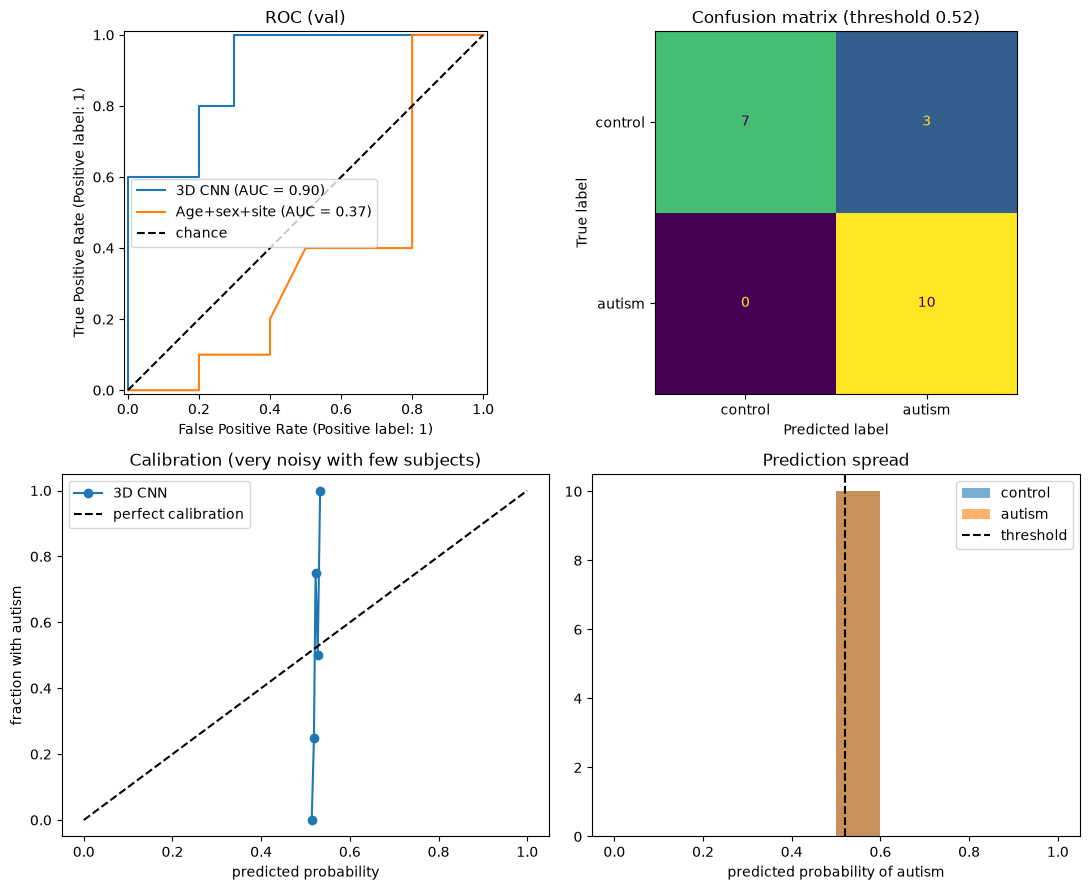

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 9))

# ROC: CNN vs confounder baseline
RocCurveDisplay.from_predictions(ev["label"], ev["prob"], name="3D CNN", ax=ax[0, 0])
RocCurveDisplay.from_predictions(ev["label"], ev["prob_conf"], name="Age+sex+site", ax=ax[0, 0])
ax[0, 0].plot([0, 1], [0, 1], "k--", label="chance")
ax[0, 0].set_title(f"ROC ({SPLIT})"); ax[0, 0].legend()

# Confusion matrix at the chosen threshold
ConfusionMatrixDisplay.from_predictions(
    ev["label"], (ev["prob"] >= THRESHOLD).astype(int),
    display_labels=["control", "autism"], ax=ax[0, 1], colorbar=False)
ax[0, 1].set_title(f"Confusion matrix (threshold {THRESHOLD:.2f})")

# Calibration: does a predicted 0.7 mean ~70% have autism?
frac_pos, mean_pred = calibration_curve(ev["label"], ev["prob"], n_bins=5, strategy="quantile")
ax[1, 0].plot(mean_pred, frac_pos, "o-", label="3D CNN")
ax[1, 0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax[1, 0].set_xlabel("predicted probability"); ax[1, 0].set_ylabel("fraction with autism")
ax[1, 0].set_title("Calibration (very noisy with few subjects)"); ax[1, 0].legend()

# How well the two groups' probabilities separate
for lab, name in [(0, "control"), (1, "autism")]:
    ax[1, 1].hist(ev.loc[ev["label"] == lab, "prob"], bins=10, range=(0, 1), alpha=0.6, label=name)
ax[1, 1].axvline(THRESHOLD, color="k", ls="--", label="threshold")
ax[1, 1].set_xlabel("predicted probability of autism"); ax[1, 1].set_title("Prediction spread")
ax[1, 1].legend()

plt.tight_layout(); plt.show()

### Saving results ###

In [9]:
out = ROOT / "results" / "evaluation"
out.mkdir(parents=True, exist_ok=True)
cnn_results.to_csv(out / f"{SPLIT}_cnn_metrics.csv")
comparison.to_csv(out / f"{SPLIT}_model_comparison.csv")
subgroups.to_csv(out / f"{SPLIT}_subgroups.csv", index=False)
ev.to_csv(out / f"{SPLIT}_subject_predictions.csv", index=False)
print("saved to", out)

saved to /Users/khedma/Documents/fall-2026-autism/results/evaluation
